# XGBoost — tuning, evaluation and test on 4 targets
Targets: **Cath** (overall CAD), **LAD**, **LCX**, **RCA**. Input: `data/processed/cad_clean.csv` produced by notebook 01 (frozen 80/20 stratified split).

Workflow: baseline → complexity / depth sweeps → feature-count sweep → GridSearchCV → RandomizedSearchCV → CV-fold study → nested CV (paper-comparable protocol) → threshold tuning → **single** test evaluation → paper methods (single / OR-rule / stacked) → permutation importance → save.

All scaling, encoding, feature selection and SMOTE sit inside one `imblearn` `Pipeline`, so every CV fold is leak-free. LAD/LCX/RCA/Cath are never inputs, except as *out-of-fold* probabilities in the paper's stacked method.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings('ignore')
import time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score, cross_validate, cross_val_predict, validation_curve)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, brier_score_loss, confusion_matrix, roc_curve, precision_recall_curve, make_scorer, ConfusionMatrixDisplay)
from sklearn.calibration import CalibrationDisplay
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
pd.set_option('display.width',220,'display.max_columns',60,'display.max_rows',200)
sns.set_theme(style='whitegrid'); SEED=42; M='xgb'
ROOT=Path('..').resolve(); OUT=ROOT/'data'/'processed'; RES=ROOT/'results'; FIG=RES/'figures'; MOD=ROOT/'models'
for p in (RES,FIG,MOD): p.mkdir(parents=True,exist_ok=True)

## 1. Load the cleaned data and rebuild the same split

In [2]:
df = pd.read_csv(OUT/'cad_clean.csv', keep_default_na=False)
TARGETS=['Cath','LAD','LCX','RCA']; AUDIT=['Cath_original','label_corrected','n_vessels']
FEATURES=[c for c in df.columns if c not in ['patient_idx','split']+TARGETS+AUDIT]
assert not set(FEATURES)&set(TARGETS+AUDIT)
tr=df[df.split=='train']; te=df[df.split=='test']
X_tr,X_te,X_all=tr[FEATURES],te[FEATURES],df[FEATURES]
Y_tr={t:tr[t].values for t in TARGETS}; Y_te={t:te[t].values for t in TARGETS}; Y_all={t:df[t].values for t in TARGETS}
print(len(FEATURES),'features | train',X_tr.shape,'| test',X_te.shape)
pd.DataFrame({'train_pos_rate':[Y_tr[t].mean() for t in TARGETS],'test_pos_rate':[Y_te[t].mean() for t in TARGETS]},index=TARGETS).round(3)

62 features | train (242, 62) | test (61, 62)


,train_pos_rate,test_pos_rate
Cath,0.715,0.721
LAD,0.583,0.590
LCX,0.388,0.410
RCA,0.376,0.377


## 2. Preprocessing definition (identical to notebook 01)

In [3]:
num_cols=['Age','Weight','Length','BMI','BP','PR','FBS','CR','TG','LDL','HDL','BUN','ESR','HB','K','Na','WBC','Lymph','Neut','PLT','EF-TTE']
skew_cols=['FBS','TG','ESR','WBC','PLT','CR','TG_HDL','NLR','LDL_HDL']
scale_cols=[c for c in num_cols if c in FEATURES and c not in skew_cols]+['pulse_pressure_proxy','risk_factor_count','ecg_abnormal_count','symptom_score']
ordinal_cols=['VHD','Function Class','Region RWMA']; nominal_cols=['BBB','CP_type','age_group']
binary_cols=[c for c in FEATURES if c not in skew_cols+scale_cols+ordinal_cols+nominal_cols]
assert sorted(skew_cols+scale_cols+ordinal_cols+nominal_cols+binary_cols)==sorted(FEATURES)
def build_preprocessor():
    return ColumnTransformer([
        ('skew',Pipeline([('log',FunctionTransformer(np.log1p,feature_names_out='one-to-one')),('sc',StandardScaler())]),skew_cols),
        ('num',StandardScaler(),scale_cols),
        ('ord',Pipeline([('enc',OrdinalEncoder(categories=[['N','mild','Moderate','Severe'],[0,1,2,3],[0,1,2,3,4]])),('sc',StandardScaler())]),ordinal_cols),
        ('nom',OneHotEncoder(handle_unknown='ignore',sparse_output=False),nominal_cols),
        ('bin','passthrough',binary_cols)],verbose_feature_names_out=False)
# the explicit fit / fit_transform / transform sequence on this split
_p=build_preprocessor(); _a=_p.fit_transform(X_tr); _b=_p.transform(X_te)
print('fit_transform(train):',_a.shape,'| transform(test):',_b.shape)

fit_transform(train): (242, 70) | transform(test): (61, 70)


## 3. Pipeline factory, CV schemes, metric helpers

In [4]:
def make_pipe(clf):
    # prep -> univariate feature selection (k tunable, 'all' = off) -> sampler (tunable: passthrough | SMOTE) -> classifier
    return ImbPipeline([('prep',build_preprocessor()),('fs',SelectKBest(f_classif,k='all')),('sampler','passthrough'),('clf',clf)])
def new_clf(): return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', tree_method='hist', n_jobs=1, random_state=SEED, verbosity=0)
cv5  = StratifiedKFold(5,shuffle=True,random_state=SEED)
cv52 = RepeatedStratifiedKFold(n_splits=5,n_repeats=2,random_state=SEED)
SCORING={'roc_auc':'roc_auc','average_precision':'average_precision','balanced_accuracy':'balanced_accuracy','f1':'f1','recall':'recall'}
spw={t:float((Y_tr[t]==0).sum()/(Y_tr[t]==1).sum()) for t in TARGETS}      # neg/pos ratio for scale_pos_weight
print({k:round(v,2) for k,v in spw.items()})

{'Cath': 0.4, 'LAD': 0.72, 'LCX': 1.57, 'RCA': 1.66}


In [5]:
def metrics_at(y,p,thr):
    yh=(p>=thr).astype(int); tn,fp,fn,tp=confusion_matrix(y,yh,labels=[0,1]).ravel()
    sens=tp/(tp+fn) if tp+fn else np.nan; spec=tn/(tn+fp) if tn+fp else np.nan
    return dict(threshold=float(thr),accuracy=accuracy_score(y,yh),balanced_acc=(sens+spec)/2,sensitivity=sens,specificity=spec,
                precision=precision_score(y,yh,zero_division=0),f1=f1_score(y,yh,zero_division=0),roc_auc=roc_auc_score(y,p),
                pr_auc=average_precision_score(y,p),brier=brier_score_loss(y,p),TP=tp,FP=fp,TN=tn,FN=fn)
def thr_youden(y,p):
    f,t,th=roc_curve(y,p); return float(th[np.argmax(t-f)])
def thr_sens(y,p,s=0.95):
    f,t,th=roc_curve(y,p); return float(th[np.where(t>=s)[0][0]])       # highest threshold reaching sensitivity s (max specificity)
def boot_ci(y,p,thr,B=1000,seed=SEED):
    rng=np.random.default_rng(seed); a,b=[],[]
    for _ in range(B):
        i=rng.integers(0,len(y),len(y))
        if len(set(y[i]))<2: continue
        a.append(roc_auc_score(y[i],p[i])); b.append(accuracy_score(y[i],(p[i]>=thr).astype(int)))
    return np.percentile(a,[2.5,97.5]),np.percentile(b,[2.5,97.5])

## 4. Baselines: Dummy vs default model (5-fold × 2 repeats, train only)

In [6]:
def cv_row(est,t,cv=cv52):
    r=cross_validate(est,X_tr,Y_tr[t],cv=cv,scoring=SCORING,n_jobs=-1)
    return {k.replace('test_',''):v.mean() for k,v in r.items() if k.startswith('test_')}
rows=[]
for t in TARGETS:
    rows.append({'target':t,'model':'Dummy',**cv_row(make_pipe(DummyClassifier(strategy='prior')),t)})
    rows.append({'target':t,'model':'default '+M,**cv_row(make_pipe(new_clf()),t)})
baseline=pd.DataFrame(rows).set_index(['target','model']).round(3); baseline

roc_auc  average_precision  balanced_accuracy     f1  recall
target model                                                                    
Cath   Dummy          0.500              0.715              0.500  0.834   1.000
       default xgb    0.933              0.973              0.815  0.910   0.936
LAD    Dummy          0.500              0.583              0.500  0.736   1.000
       default xgb    0.847              0.874              0.785  0.833   0.866
LCX    Dummy          0.500              0.388              0.500  0.000   0.000
       default xgb    0.691              0.560              0.608  0.487   0.442
RCA    Dummy          0.500              0.376              0.500  0.000   0.000
       default xgb    0.729              0.602              0.645  0.529   0.467

## 5. Complexity / depth sweeps (train vs CV ROC-AUC)

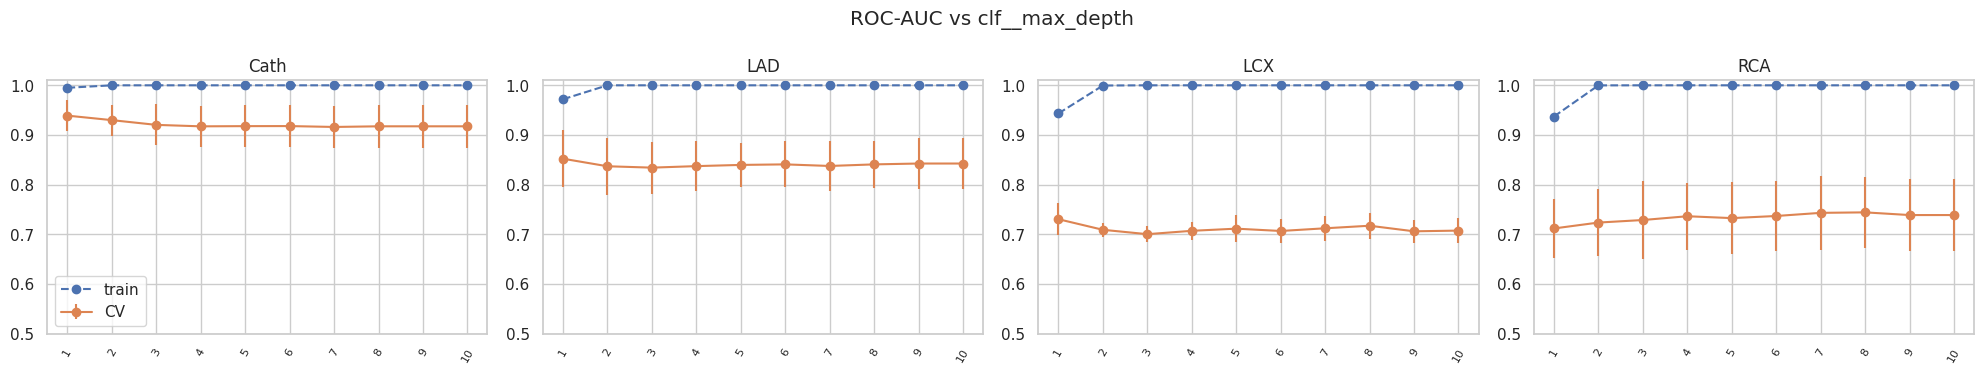

In [7]:
def sweep(param,values,title,fname):
    fig,axes=plt.subplots(1,4,figsize=(20,3.8)); out={}
    for ax,t in zip(axes,TARGETS):
        tr_s,cv_s=validation_curve(make_pipe(new_clf()),X_tr,Y_tr[t],param_name=param,param_range=values,cv=cv5,scoring='roc_auc',n_jobs=-1)
        xs=np.arange(len(values)); out[t]=pd.DataFrame({'value':[str(v) for v in values],'train_auc':tr_s.mean(1),'cv_auc':cv_s.mean(1),'cv_std':cv_s.std(1)})
        ax.plot(xs,tr_s.mean(1),'o--',label='train'); ax.errorbar(xs,cv_s.mean(1),cv_s.std(1),fmt='o-',label='CV')
        ax.set_xticks(xs); ax.set_xticklabels([str(v) for v in values],rotation=60,fontsize=8); ax.set_title(f'{t}'); ax.set_ylim(0.5,1.01)
    axes[0].legend(); fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG/f'xgb_{fname}.png',dpi=110); plt.show(); return out
p1,v1=('clf__max_depth', list(range(1,11)))
sw1=sweep(p1,v1,f'ROC-AUC vs {p1}','sweep1')

In [8]:
pd.concat({t:sw1[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
1         0.995  0.939     0.972  0.852     0.943  0.730     0.937  0.712
2         1.000  0.930     1.000  0.837     1.000  0.709     1.000  0.724
3         1.000  0.920     1.000  0.834     1.000  0.700     1.000  0.729
4         1.000  0.917     1.000  0.837     1.000  0.707     1.000  0.736
5         1.000  0.918     1.000  0.840     1.000  0.711     1.000  0.733
6         1.000  0.918     1.000  0.841     1.000  0.707     1.000  0.737
7         1.000  0.916     1.000  0.838     1.000  0.712     1.000  0.743
8         1.000  0.917     1.000  0.841     1.000  0.717     1.000  0.744
9         1.000  0.917     1.000  0.843     1.000  0.706     1.000  0.739
10        1.000  0.917     1.000  0.843     1.000  0.708     1.000  0.739

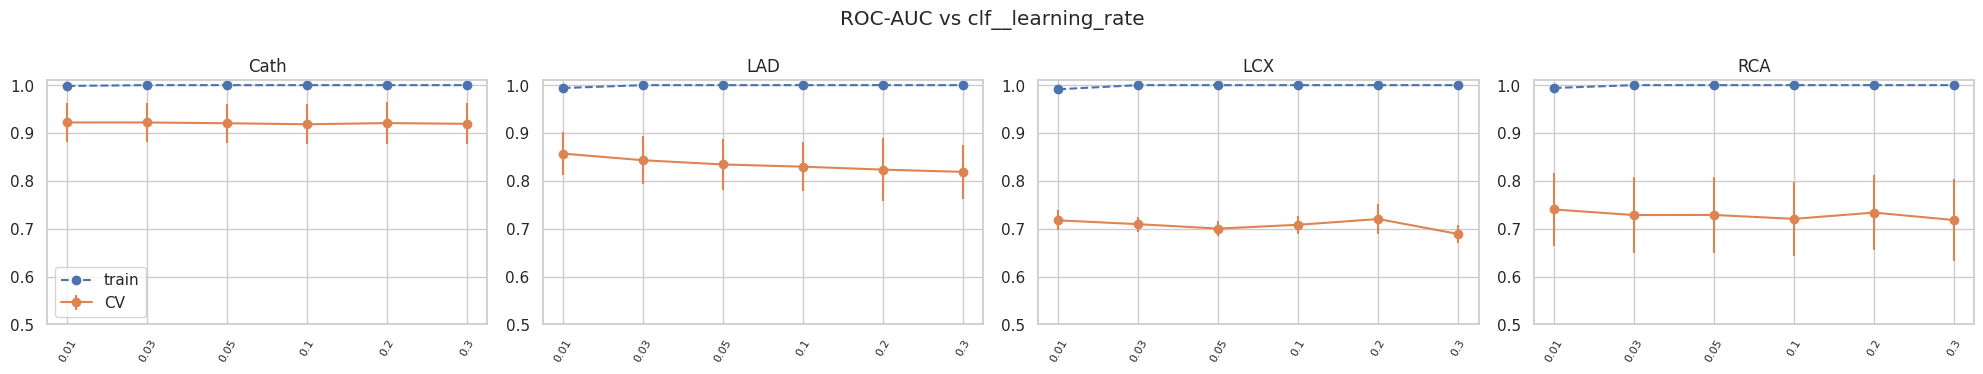

In [9]:
p2,v2=('clf__learning_rate', [0.01,0.03,0.05,0.1,0.2,0.3])
sw2=sweep(p2,v2,f'ROC-AUC vs {p2}','sweep2')

In [10]:
pd.concat({t:sw2[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
0.01      0.998  0.922     0.994  0.857     0.991  0.718     0.994  0.740
0.03      1.000  0.922     1.000  0.843     1.000  0.709     1.000  0.729
0.05      1.000  0.920     1.000  0.834     1.000  0.700     1.000  0.729
0.1       1.000  0.918     1.000  0.830     1.000  0.708     1.000  0.721
0.2       1.000  0.921     1.000  0.823     1.000  0.720     1.000  0.734
0.3       1.000  0.919     1.000  0.819     1.000  0.689     1.000  0.718

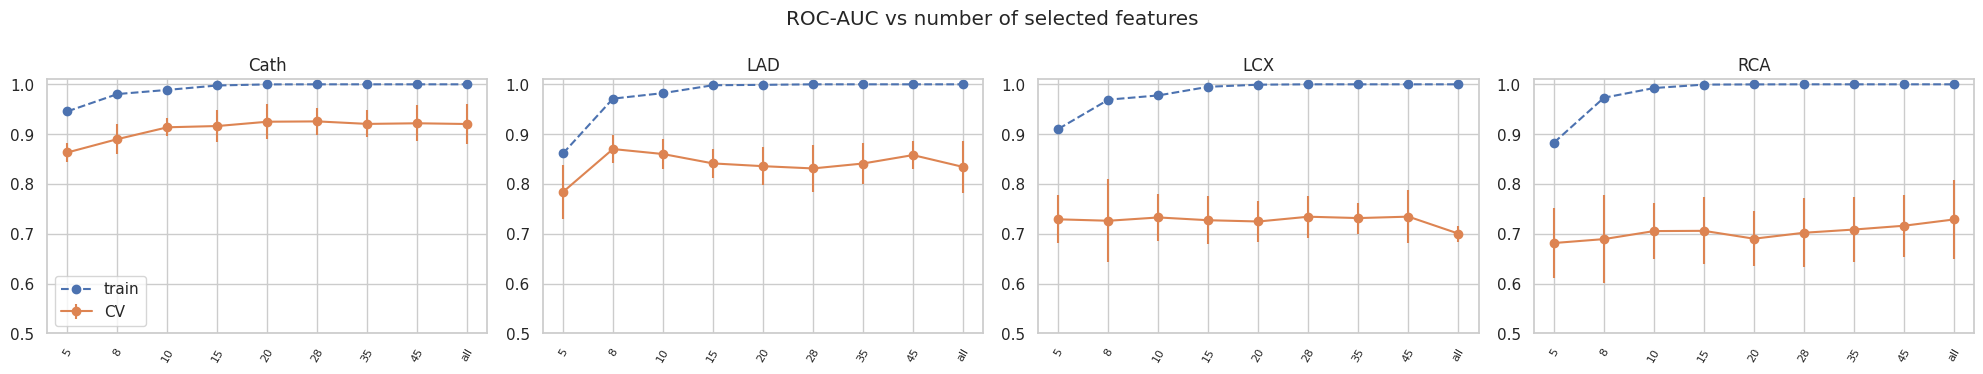

Cath              LAD              LCX              RCA       
      train_auc cv_auc train_auc cv_auc train_auc cv_auc train_auc cv_auc
value                                                                    
5         0.946  0.863     0.861  0.784     0.911  0.729     0.883  0.682
8         0.980  0.890     0.971  0.870     0.969  0.726     0.973  0.689
10        0.989  0.914     0.982  0.860     0.978  0.733     0.993  0.705
15        0.998  0.916     0.998  0.841     0.995  0.727     0.999  0.706
20        1.000  0.925     0.999  0.836     0.999  0.725     1.000  0.690
28        1.000  0.926     1.000  0.831     1.000  0.734     1.000  0.702
35        1.000  0.921     1.000  0.841     1.000  0.732     1.000  0.709
45        1.000  0.922     1.000  0.858     1.000  0.734     1.000  0.716
all       1.000  0.920     1.000  0.834     1.000  0.700     1.000  0.729

In [11]:
# number of selected features (SelectKBest inside the pipeline)
ks=[5,8,10,15,20,28,35,45,'all']
sw3=sweep('fs__k',ks,'ROC-AUC vs number of selected features','sweep_k')
pd.concat({t:sw3[t].set_index('value')[['train_auc','cv_auc']] for t in TARGETS},axis=1).round(3)

## 6. GridSearchCV (focused grid, 5×2 repeated CV, 5 metrics, refit on ROC-AUC)

In [12]:
def param_grid(spw):
    return {'fs__k':[20,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__max_depth':[2,3,4,6],'clf__learning_rate':[0.03,0.1],
            'clf__n_estimators':[150,400],'clf__subsample':[0.7,1.0],'clf__colsample_bytree':[0.6,1.0],'clf__scale_pos_weight':[1,spw]}
def param_space(spw):
    return {'fs__k':[10,15,20,28,35,45,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)],'clf__max_depth':randint(1,10),
            'clf__learning_rate':loguniform(0.01,0.3),'clf__n_estimators':randint(80,700),'clf__subsample':uniform(0.5,0.5),
            'clf__colsample_bytree':uniform(0.4,0.6),'clf__min_child_weight':randint(1,10),'clf__gamma':uniform(0,3),
            'clf__reg_alpha':loguniform(1e-3,10),'clf__reg_lambda':loguniform(1e-2,30),'clf__scale_pos_weight':[1,float(np.sqrt(spw)),spw]}
for t in TARGETS:
    g=param_grid(spw[t]); size=int(np.sum([np.prod([len(v) for v in d.values()]) for d in (g if isinstance(g,list) else [g])]))
    print(t,'grid combinations:',size,'-> fits:',size*10)

Cath grid combinations: 512 -> fits: 5120
LAD grid combinations: 512 -> fits: 5120
LCX grid combinations: 512 -> fits: 5120
RCA grid combinations: 512 -> fits: 5120


In [13]:
searches={t:{} for t in TARGETS}
for t in TARGETS:
    t0=time.time()
    gs=GridSearchCV(make_pipe(new_clf()),param_grid(spw[t]),scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,verbose=0)
    gs.fit(X_tr,Y_tr[t]); searches[t]['grid']=gs
    pd.DataFrame(gs.cv_results_).to_csv(RES/f'{M}_cv_grid_{t}.csv',index=False)
    print(f'{t}: best CV AUC={gs.best_score_:.4f}  ({time.time()-t0:.0f}s, {len(gs.cv_results_["params"])} combos)')

Cath: best CV AUC=0.9478  (28s, 512 combos)


LAD: best CV AUC=0.8718  (27s, 512 combos)


LCX: best CV AUC=0.7176  (29s, 512 combos)


RCA: best CV AUC=0.7524  (30s, 512 combos)


## 7. RandomizedSearchCV (wide space, many more combinations)

In [14]:
N_ITER=250
for t in TARGETS:
    t0=time.time()
    rs=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=N_ITER,scoring=SCORING,refit='roc_auc',cv=cv52,n_jobs=-1,random_state=SEED,verbose=0)
    rs.fit(X_tr,Y_tr[t]); searches[t]['random']=rs
    pd.DataFrame(rs.cv_results_).to_csv(RES/f'{M}_cv_random_{t}.csv',index=False)
    print(f'{t}: best CV AUC={rs.best_score_:.4f}  ({time.time()-t0:.0f}s)')

Cath: best CV AUC=0.9447  (11s)


LAD: best CV AUC=0.8800  (11s)


LCX: best CV AUC=0.7311  (12s)


RCA: best CV AUC=0.7702  (12s)


## 8. Pick the best configuration per target

In [15]:
best_est,rows={},[]
for t in TARGETS:
    g,r=searches[t]['grid'],searches[t]['random']
    win,name=(g,'grid') if g.best_score_>=r.best_score_ else (r,'random')
    best_est[t]=win.best_estimator_; i=win.best_index_; cr=win.cv_results_
    rows.append({'target':t,'winner':name,'cv_roc_auc':cr['mean_test_roc_auc'][i],'cv_pr_auc':cr['mean_test_average_precision'][i],
                 'cv_bal_acc':cr['mean_test_balanced_accuracy'][i],'cv_f1':cr['mean_test_f1'][i],'cv_recall':cr['mean_test_recall'][i],
                 'grid_auc':g.best_score_,'random_auc':r.best_score_})
best_tbl=pd.DataFrame(rows).set_index('target').round(4); best_tbl

,winner,cv_roc_auc,cv_pr_auc,cv_bal_acc,cv_f1,cv_recall,grid_auc,random_auc
target,,,,,,,,
Cath,grid,0.9478,0.9802,0.8464,0.9203,0.9334,0.9478,0.9447
LAD,random,0.8800,0.8997,0.7950,0.8446,0.8865,0.8718,0.8800
LCX,random,0.7311,0.6112,0.6612,0.5775,0.5588,0.7176,0.7311
RCA,random,0.7702,0.6659,0.6827,0.6145,0.6538,0.7524,0.7702


In [16]:
best_params=pd.DataFrame({t:{k:str(v) for k,v in best_est[t].get_params().items() if k.startswith(('clf__','fs__k','sampler'))
                                 and not isinstance(v,(dict,)) and k not in ('sampler__random_state',)} for t in TARGETS}); best_params

,Cath,LAD,LCX,RCA
sampler,SMOTE(random_state=42),passthrough,passthrough,passthrough
fs__k,all,10,45,35
sampler__k_neighbors,5,NaN,NaN,NaN
sampler__sampling_strategy,auto,NaN,NaN,NaN
clf__objective,binary:logistic,binary:logistic,binary:logistic,binary:logistic
clf__base_score,None,None,None,None
clf__booster,None,None,None,None
clf__callbacks,None,None,None,None
clf__colsample_bylevel,None,None,None,None
clf__colsample_bynode,None,None,None,None


In [17]:
# top-5 combinations per target (from both searches)
for t in TARGETS:
    parts=[]
    for nm in ('grid','random'):
        d=pd.DataFrame(searches[t][nm].cv_results_); d['search']=nm; parts.append(d)
    d=pd.concat(parts).sort_values('mean_test_roc_auc',ascending=False).head(5)
    print('==',t); print(d[['search','mean_test_roc_auc','std_test_roc_auc','mean_test_balanced_accuracy','mean_test_recall','params']].to_string(index=False,max_colwidth=160))

== Cath
search  mean_test_roc_auc  std_test_roc_auc  mean_test_balanced_accuracy  mean_test_recall                                                                                                                                                           params
  grid           0.947820          0.029212                     0.846351          0.933361 {'clf__colsample_bytree': 0.6, 'clf__learning_rate': 0.03, 'clf__max_depth': 2, 'clf__n_estimators': 400, 'clf__scale_pos_weight': 1, 'clf__subsample': 0.7, ...
  grid           0.946882          0.032905                     0.861942          0.942017 {'clf__colsample_bytree': 1.0, 'clf__learning_rate': 0.03, 'clf__max_depth': 2, 'clf__n_estimators': 400, 'clf__scale_pos_weight': 1, 'clf__subsample': 0.7, ...
random           0.944743          0.030663                     0.841034          0.930420 {'clf__colsample_bytree': 0.48182288535206186, 'clf__gamma': 0.043633997003645786, 'clf__learning_rate': 0.03295037296651692, 'clf__max_depth': 2

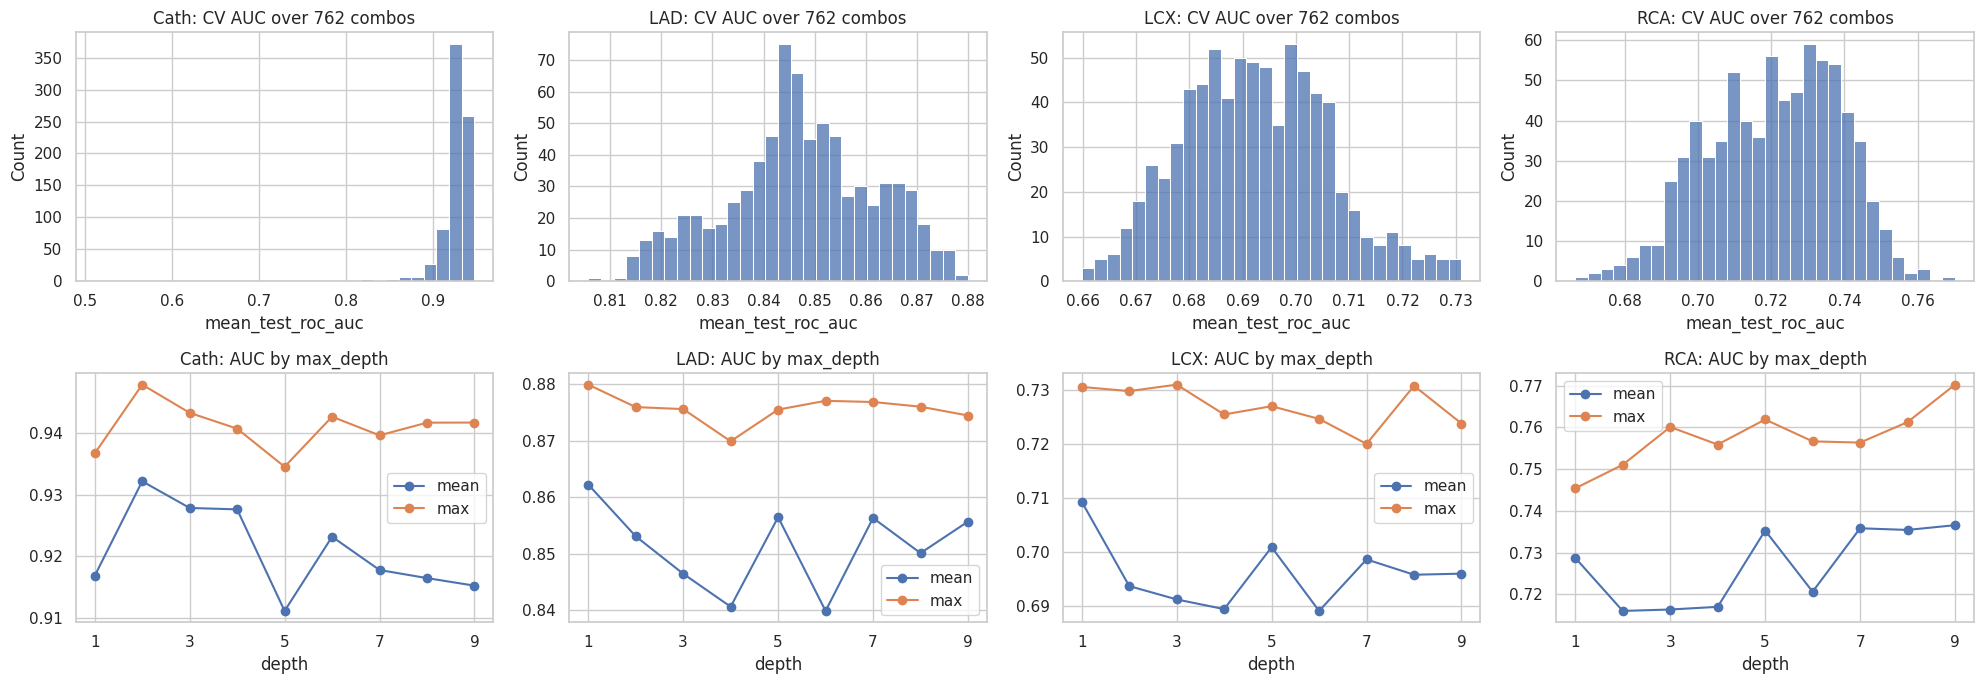

In [18]:
# distribution of CV AUC over all tried combinations + effect of depth if it was tuned
fig,axes=plt.subplots(2,4,figsize=(20,7))
for j,t in enumerate(TARGETS):
    d=pd.concat([pd.DataFrame(searches[t][n_].cv_results_) for n_ in ('grid','random')])
    sns.histplot(d.mean_test_roc_auc,bins=30,ax=axes[0,j]); axes[0,j].set_title(f'{t}: CV AUC over {len(d)} combos')
    col=[c for c in d.columns if c.endswith('max_depth')]
    if col:
        dd=d.assign(depth=d[col[0]].astype(str)).groupby('depth').mean_test_roc_auc.agg(['mean','max'])
        dd=dd.loc[sorted(dd.index,key=lambda s:(s=='None',float(s) if s not in ('None',) else 99))]
        dd.plot(ax=axes[1,j],marker='o'); axes[1,j].set_title(f'{t}: AUC by max_depth')
    else:
        d.assign(k=d['param_fs__k'].astype(str)).groupby('k').mean_test_roc_auc.max().plot.bar(ax=axes[1,j]); axes[1,j].set_title(f'{t}: best AUC by k')
plt.tight_layout(); plt.savefig(FIG/f'{M}_search_overview.png',dpi=110); plt.show()

## 9. Effect of the number of CV folds (best configuration, train only)

In [19]:
schemes={'3-fold':StratifiedKFold(3,shuffle=True,random_state=SEED),'5-fold':StratifiedKFold(5,shuffle=True,random_state=SEED),
         '7-fold':StratifiedKFold(7,shuffle=True,random_state=SEED),'10-fold':StratifiedKFold(10,shuffle=True,random_state=SEED),
         '5x3 repeated':RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED),'10x3 repeated':RepeatedStratifiedKFold(n_splits=10,n_repeats=3,random_state=SEED)}
rows=[]
for t in TARGETS:
    for nm,cv in schemes.items():
        s=cross_validate(clone(best_est[t]),X_tr,Y_tr[t],cv=cv,scoring={'auc':'roc_auc','acc':'accuracy','bal':'balanced_accuracy'},n_jobs=-1)
        rows.append({'target':t,'cv':nm,'auc_mean':s['test_auc'].mean(),'auc_std':s['test_auc'].std(),'acc_mean':s['test_acc'].mean(),'bal_acc_mean':s['test_bal'].mean()})
fold_tbl=pd.DataFrame(rows); fold_tbl.to_csv(RES/f'{M}_cv_fold_study.csv',index=False)
fold_tbl.pivot(index='cv',columns='target',values='auc_mean').loc[list(schemes)].round(4)

target,Cath,LAD,LCX,RCA
cv,,,,
3-fold,0.9359,0.8691,0.7001,0.7551
5-fold,0.9353,0.8760,0.7363,0.7687
7-fold,0.9567,0.8728,0.7480,0.7757
10-fold,0.9522,0.8755,0.7345,0.7674
5x3 repeated,0.9485,0.8779,0.7243,0.7637
10x3 repeated,0.9499,0.8800,0.7260,0.7605


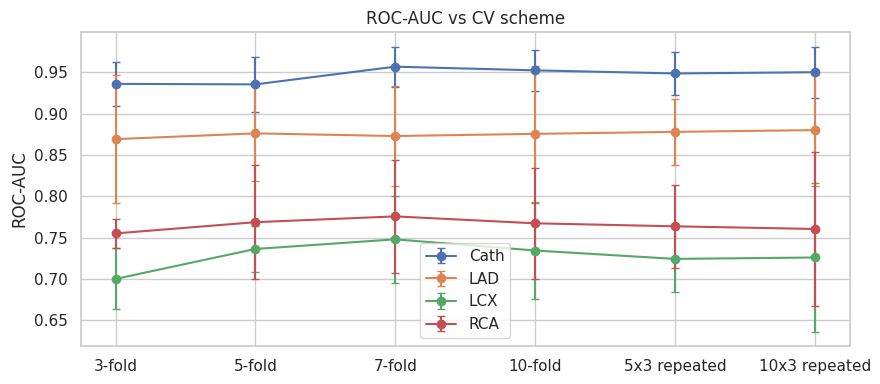

In [20]:
fig,ax=plt.subplots(figsize=(9,4))
for t in TARGETS:
    d=fold_tbl[fold_tbl.target==t]; ax.errorbar(range(len(d)),d.auc_mean,d.auc_std,marker='o',label=t,capsize=3)
ax.set_xticks(range(len(schemes))); ax.set_xticklabels(list(schemes)); ax.set_ylabel('ROC-AUC'); ax.legend(); ax.set_title('ROC-AUC vs CV scheme'); plt.tight_layout(); plt.show()

## 10. Nested CV on all 303 patients (paper-comparable protocol)
The paper reports 10-fold CV on all data. Here every outer fold tunes hyper-parameters (feature count, sampler, model parameters) on its own training part only, so the numbers are not tuned on the fold that scores them. Threshold = 0.5.

In [21]:
spec_scorer=make_scorer(recall_score,pos_label=0)
NEST_SCORING={'accuracy':'accuracy','balanced_acc':'balanced_accuracy','sensitivity':'recall','specificity':spec_scorer,'precision':'precision','f1':'f1','roc_auc':'roc_auc'}
outer=StratifiedKFold(10,shuffle=True,random_state=SEED); nested_rows=[]
for t in TARGETS:
    t0=time.time()
    inner=RandomizedSearchCV(make_pipe(new_clf()),param_space(spw[t]),n_iter=25,scoring='roc_auc',cv=StratifiedKFold(3,shuffle=True,random_state=SEED),n_jobs=1,random_state=SEED)
    r=cross_validate(inner,X_all,Y_all[t],cv=outer,scoring=NEST_SCORING,n_jobs=-1)
    row={'target':t}; row.update({k.replace('test_',''):r[k].mean() for k in r if k.startswith('test_')}); row.update({k.replace('test_','')+'_std':r[k].std() for k in r if k.startswith('test_')})
    nested_rows.append(row); print(t,f"acc={row['accuracy']:.3f} sens={row['sensitivity']:.3f} spec={row['specificity']:.3f} auc={row['roc_auc']:.3f} ({time.time()-t0:.0f}s)")
nested=pd.DataFrame(nested_rows).set_index('target'); nested.to_csv(RES/f'{M}_nested_cv.csv'); nested[[c for c in nested if not c.endswith('_std')]].round(4)

Cath acc=0.872 sens=0.908 spec=0.781 auc=0.933 (4s)


LAD acc=0.740 sens=0.767 spec=0.697 auc=0.826 (3s)


LCX acc=0.630 sens=0.538 spec=0.690 auc=0.668 (4s)


RCA acc=0.676 sens=0.587 spec=0.731 auc=0.719 (4s)


,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc
target,,,,,,,
Cath,0.8716,0.8441,0.9076,0.7806,0.9158,0.9099,0.9327
LAD,0.7397,0.7324,0.7673,0.6974,0.7875,0.7719,0.8261
LCX,0.6304,0.6138,0.5379,0.6898,0.5248,0.5270,0.6679
RCA,0.6761,0.6592,0.5871,0.7313,0.5981,0.5818,0.7193


## 11. Decision threshold from out-of-fold *train* probabilities

In [22]:
def oof_proba(est,X,y,seeds=(0,1,2)):
    P=np.zeros(len(y))
    for s in seeds: P+=cross_val_predict(clone(est),X,y,cv=StratifiedKFold(5,shuffle=True,random_state=s),method='predict_proba',n_jobs=-1)[:,1]
    return P/len(seeds)
oof={t:oof_proba(best_est[t],X_tr,Y_tr[t]) for t in TARGETS}
THR={t:{'default_0.5':0.5,'youden':thr_youden(Y_tr[t],oof[t]),'sens>=0.95':thr_sens(Y_tr[t],oof[t],0.95)} for t in TARGETS}
pd.DataFrame(THR).T.round(3)

,default_0.5,youden,sens>=0.95
Cath,0.5,0.654,0.353
LAD,0.5,0.544,0.384
LCX,0.5,0.432,0.181
RCA,0.5,0.425,0.371


In [23]:
pd.DataFrame({(t,k):metrics_at(Y_tr[t],oof[t],v) for t in TARGETS for k,v in THR[t].items()}).T[['threshold','accuracy','sensitivity','specificity','roc_auc']].round(3)

threshold  accuracy  sensitivity  specificity  roc_auc
Cath default_0.5      0.500     0.901        0.942        0.797    0.952
     youden           0.654     0.897        0.902        0.884    0.952
     sens>=0.95       0.353     0.880        0.960        0.681    0.952
LAD  default_0.5      0.500     0.806        0.879        0.703    0.869
     youden           0.544     0.814        0.851        0.762    0.869
     sens>=0.95       0.384     0.781        0.950        0.545    0.869
LCX  default_0.5      0.500     0.674        0.521        0.770    0.734
     youden           0.432     0.694        0.670        0.709    0.734
     sens>=0.95       0.181     0.537        0.957        0.270    0.734
RCA  default_0.5      0.500     0.661        0.626        0.682    0.738
     youden           0.425     0.661        0.912        0.510    0.738
     sens>=0.95       0.371     0.587        0.956        0.364    0.738

## 12. Final evaluation on the held-out test set (touched once)

In [24]:
test_proba={}
for t in TARGETS:
    best_est[t].fit(X_tr,Y_tr[t]); test_proba[t]=best_est[t].predict_proba(X_te)[:,1]
rows=[]
for t in TARGETS:
    for k,thr in THR[t].items():
        m=metrics_at(Y_te[t],test_proba[t],thr); (alo,ahi),(clo,chi)=boot_ci(Y_te[t],test_proba[t],thr)
        rows.append({'target':t,'strategy':'direct','threshold_rule':k,**m,'auc_ci':f'[{alo:.3f},{ahi:.3f}]','acc_ci':f'[{clo:.3f},{chi:.3f}]'})
test_tbl=pd.DataFrame(rows); test_tbl.to_csv(RES/f'{M}_test_metrics_direct.csv',index=False)
test_tbl[['target','threshold_rule','threshold','accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc','brier','auc_ci','acc_ci']].round(3)

,target,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,auc_ci,acc_ci
0,Cath,default_0.5,0.500,0.820,0.749,0.909,0.588,0.851,0.879,0.920,0.970,0.108,"[0.846,0.978]","[0.721,0.918]"
1,Cath,youden,0.654,0.869,0.837,0.909,0.765,0.909,0.909,0.920,0.970,0.108,"[0.846,0.978]","[0.787,0.951]"
2,Cath,sens>=0.95,0.353,0.836,0.742,0.955,0.529,0.840,0.894,0.920,0.970,0.108,"[0.846,0.978]","[0.738,0.918]"
3,LAD,default_0.5,0.500,0.721,0.697,0.833,0.560,0.732,0.779,0.791,0.840,0.181,"[0.665,0.900]","[0.606,0.820]"
4,LAD,youden,0.544,0.738,0.717,0.833,0.600,0.750,0.789,0.791,0.840,0.181,"[0.665,0.900]","[0.623,0.836]"
5,LAD,sens>=0.95,0.384,0.721,0.666,0.972,0.360,0.686,0.805,0.791,0.840,0.181,"[0.665,0.900]","[0.623,0.836]"
6,LCX,default_0.5,0.500,0.705,0.695,0.640,0.750,0.640,0.640,0.712,0.581,0.227,"[0.577,0.836]","[0.590,0.820]"
7,LCX,youden,0.432,0.590,0.604,0.680,0.528,0.500,0.576,0.712,0.581,0.227,"[0.577,0.836]","[0.475,0.705]"
8,LCX,sens>=0.95,0.181,0.607,0.661,0.960,0.361,0.511,0.667,0.712,0.581,0.227,"[0.577,0.836]","[0.475,0.721]"
9,RCA,default_0.5,0.500,0.574,0.564,0.522,0.605,0.444,0.480,0.640,0.567,0.229,"[0.502,0.776]","[0.459,0.689]"


In [25]:
# majority-class reference on the same test set
pd.DataFrame({t:{'majority-class accuracy':max(Y_te[t].mean(),1-Y_te[t].mean()),'model accuracy (youden)':test_tbl[(test_tbl.target==t)&(test_tbl.threshold_rule=='youden')].accuracy.iloc[0]} for t in TARGETS}).T.round(3)

,majority-class accuracy,model accuracy (youden)
Cath,0.721,0.869
LAD,0.590,0.738
LCX,0.590,0.590
RCA,0.623,0.557


## 13. Curves and confusion matrices

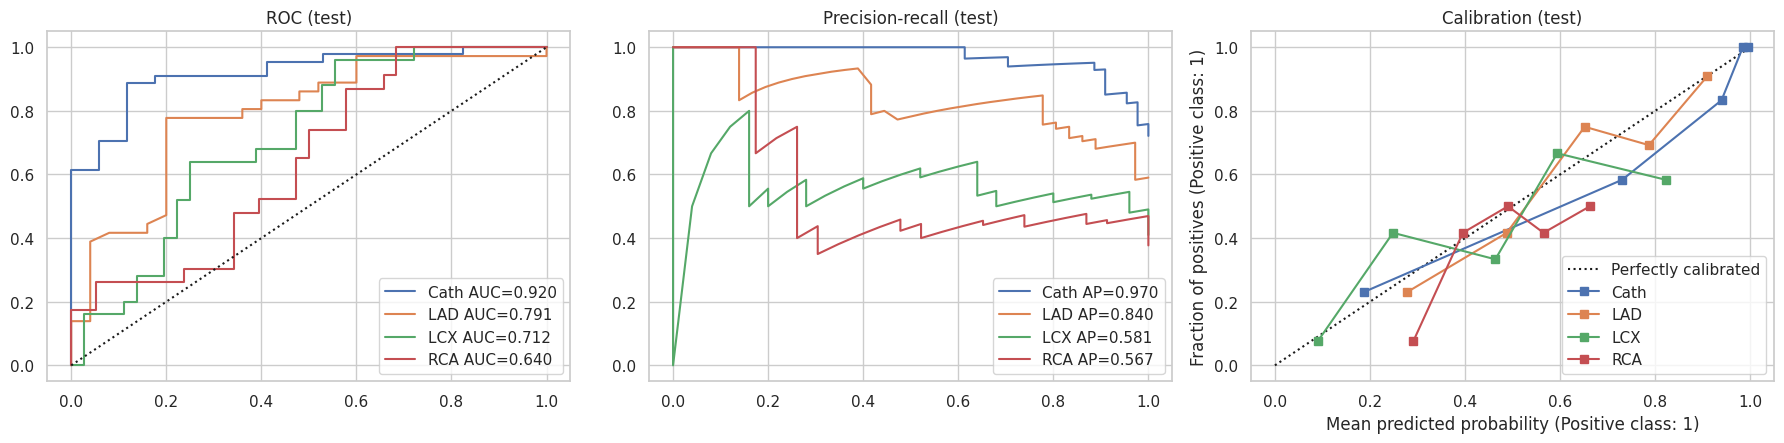

In [26]:
fig,axes=plt.subplots(1,3,figsize=(18,4.6))
for t in TARGETS:
    f,s,_=roc_curve(Y_te[t],test_proba[t]); axes[0].plot(f,s,label=f'{t} AUC={roc_auc_score(Y_te[t],test_proba[t]):.3f}')
    p,r,_=precision_recall_curve(Y_te[t],test_proba[t]); axes[1].plot(r,p,label=f'{t} AP={average_precision_score(Y_te[t],test_proba[t]):.3f}')
    CalibrationDisplay.from_predictions(Y_te[t],test_proba[t],n_bins=5,strategy='quantile',ax=axes[2],name=t)
axes[0].plot([0,1],[0,1],'k:'); axes[0].set_title('ROC (test)'); axes[1].set_title('Precision-recall (test)'); axes[2].set_title('Calibration (test)')
for a in axes[:2]: a.legend()
plt.tight_layout(); plt.savefig(FIG/f'{M}_curves.png',dpi=110); plt.show()

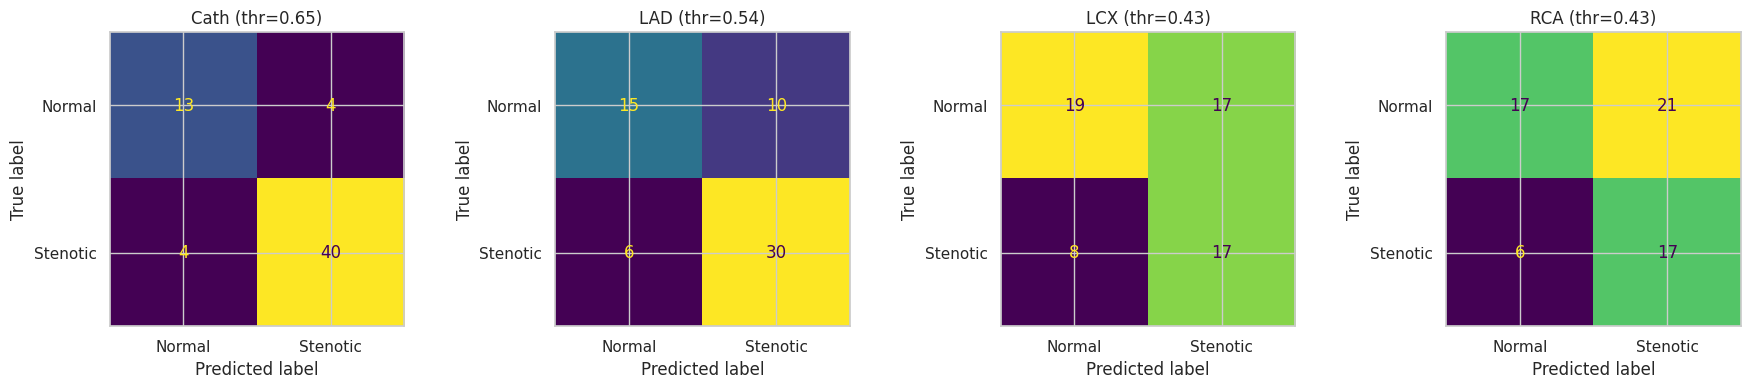

In [27]:
fig,axes=plt.subplots(1,4,figsize=(18,4))
for ax,t in zip(axes,TARGETS):
    thr=THR[t]['youden']; ConfusionMatrixDisplay.from_predictions(Y_te[t],(test_proba[t]>=thr).astype(int),ax=ax,colorbar=False,display_labels=['Normal','Stenotic']); ax.set_title(f'{t} (thr={thr:.2f})')
plt.tight_layout(); plt.savefig(FIG/f'{M}_confusion.png',dpi=110); plt.show()

## 14. Paper methods on this model family
1. **Single classifier** – Cath model only (section 12).
2. **Three-classifier OR rule** – `CT = LAD ∨ LCX ∨ RCA` (Eq. 1 of the paper).
3. **Feature-engineering (stacked) method** – out-of-fold probabilities of the LAD/LCX/RCA/CAD models are appended to the clinical features and a final CAD classifier is trained on them. Train probabilities are out-of-fold, test probabilities come from models fitted on the full train set.

In [28]:
# 2) OR rule
rows=[]
for rule in ('default_0.5','youden'):
    pred=np.zeros(len(te),int)
    for t in ['LAD','LCX','RCA']: pred|=(test_proba[t]>=THR[t][rule]).astype(int)
    score=1-np.prod([1-test_proba[t] for t in ['LAD','LCX','RCA']],axis=0)               # P(at least one stenotic), independence assumption
    yh=pred; tn,fp,fn,tp=confusion_matrix(Y_te['Cath'],yh,labels=[0,1]).ravel()
    rows.append({'target':'Cath','strategy':'OR-rule','threshold_rule':rule,'accuracy':accuracy_score(Y_te['Cath'],yh),'balanced_acc':balanced_accuracy_score(Y_te['Cath'],yh),
                 'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),'precision':precision_score(Y_te['Cath'],yh,zero_division=0),'f1':f1_score(Y_te['Cath'],yh),
                 'roc_auc':roc_auc_score(Y_te['Cath'],score),'pr_auc':average_precision_score(Y_te['Cath'],score),'brier':brier_score_loss(Y_te['Cath'],score),'TP':tp,'FP':fp,'TN':tn,'FN':fn})
or_tbl=pd.DataFrame(rows); or_tbl.round(3)

,target,strategy,threshold_rule,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,OR-rule,default_0.5,0.852,0.807,0.909,0.706,0.889,0.899,0.906,0.962,0.141,40,5,12,4
1,Cath,OR-rule,youden,0.836,0.778,0.909,0.647,0.870,0.889,0.906,0.962,0.141,40,6,11,4


In [29]:
# 3) stacked method
PCOLS=['p_LAD','p_LCX','p_RCA','p_CAD']
oof_tr={t:cross_val_predict(clone(best_est[t]),X_tr,Y_tr[t],cv=StratifiedKFold(5,shuffle=True,random_state=SEED),method='predict_proba',n_jobs=-1)[:,1] for t in TARGETS}
def augment(X,P):
    A=X.copy()
    for c,t in zip(PCOLS,['LAD','LCX','RCA','Cath']): A[c]=P[t]
    return A
Xa_tr=augment(X_tr,oof_tr); Xa_te=augment(X_te,test_proba)
def meta_pipe():
    p=clone(best_est['Cath']); p.set_params(prep=ColumnTransformer([('base',build_preprocessor(),FEATURES),('probs','passthrough',PCOLS)],verbose_feature_names_out=False))
    return p
mg=GridSearchCV(meta_pipe(),{'fs__k':[4,8,12,20,32,'all'],'sampler':['passthrough',SMOTE(random_state=SEED)]},scoring='roc_auc',cv=cv52,n_jobs=-1).fit(Xa_tr,Y_tr['Cath'])
meta=mg.best_estimator_; print('stacked CV AUC:',round(mg.best_score_,4),'| params:',{k:v for k,v in mg.best_params_.items()})
oof_meta=oof_proba(meta,Xa_tr,Y_tr['Cath']); thr_meta={'default_0.5':0.5,'youden':thr_youden(Y_tr['Cath'],oof_meta),'sens>=0.95':thr_sens(Y_tr['Cath'],oof_meta,0.95)}
meta.fit(Xa_tr,Y_tr['Cath']); p_meta=meta.predict_proba(Xa_te)[:,1]
st=pd.DataFrame([{'target':'Cath','strategy':'stacked (paper FE)','threshold_rule':k,**metrics_at(Y_te['Cath'],p_meta,v)} for k,v in thr_meta.items()]); st.round(3)

stacked CV AUC: 0.9245 | params: {'fs__k': 4, 'sampler': 'passthrough'}


,target,strategy,threshold_rule,threshold,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc,brier,TP,FP,TN,FN
0,Cath,stacked (paper FE),default_0.5,0.500,0.869,0.819,0.932,0.706,0.891,0.911,0.892,0.952,0.119,41,5,12,3
1,Cath,stacked (paper FE),youden,0.629,0.803,0.773,0.841,0.706,0.881,0.860,0.892,0.952,0.119,37,5,12,7
2,Cath,stacked (paper FE),sens>=0.95,0.261,0.836,0.742,0.955,0.529,0.840,0.894,0.892,0.952,0.119,42,8,9,2


In [30]:
# compare the three strategies for CAD with the paper's SVM numbers (10-fold CV on 500 patients; ours: held-out test of 61)
paper=pd.DataFrame([{'strategy':'PAPER single (SVM)','accuracy':.850,'sensitivity':.894,'specificity':.768,'roc_auc':.81},
                    {'strategy':'PAPER three-classifier (SVM)','accuracy':.810,'sensitivity':.814,'specificity':.798,'roc_auc':.87},
                    {'strategy':'PAPER feature engineering (SVM)','accuracy':.964,'sensitivity':1.0,'specificity':.881,'roc_auc':.92}])
ours=pd.concat([test_tbl[test_tbl.target=='Cath'].assign(strategy=lambda d:'direct @'+d.threshold_rule),or_tbl.assign(strategy=lambda d:'OR-rule @'+d.threshold_rule),
                st.assign(strategy=lambda d:'stacked @'+d.threshold_rule)])[['strategy','accuracy','sensitivity','specificity','roc_auc']]
cmp_tbl=pd.concat([paper,ours.assign(strategy=lambda d:'OURS '+M+' '+d.strategy)]).set_index('strategy'); cmp_tbl.round(3)

,accuracy,sensitivity,specificity,roc_auc
strategy,,,,
PAPER single (SVM),0.850,0.894,0.768,0.810
PAPER three-classifier (SVM),0.810,0.814,0.798,0.870
PAPER feature engineering (SVM),0.964,1.000,0.881,0.920
OURS xgb direct @default_0.5,0.820,0.909,0.588,0.920
OURS xgb direct @youden,0.869,0.909,0.765,0.920
OURS xgb direct @sens>=0.95,0.836,0.955,0.529,0.920
OURS xgb OR-rule @default_0.5,0.852,0.909,0.706,0.906
OURS xgb OR-rule @youden,0.836,0.909,0.647,0.906
OURS xgb stacked @default_0.5,0.869,0.932,0.706,0.892


In [31]:
all_rows=pd.concat([test_tbl,or_tbl,st]); all_rows.to_csv(RES/f'{M}_test_metrics.csv',index=False)
nested.loc[['Cath']].round(3).rename(index={'Cath':'OURS nested 10-fold CV (303 pts, thr 0.5)'})[['accuracy','sensitivity','specificity','roc_auc']]

,accuracy,sensitivity,specificity,roc_auc
target,,,,
"OURS nested 10-fold CV (303 pts, thr 0.5)",0.872,0.908,0.781,0.933


## 15. Permutation importance on the test set (raw features, per target)

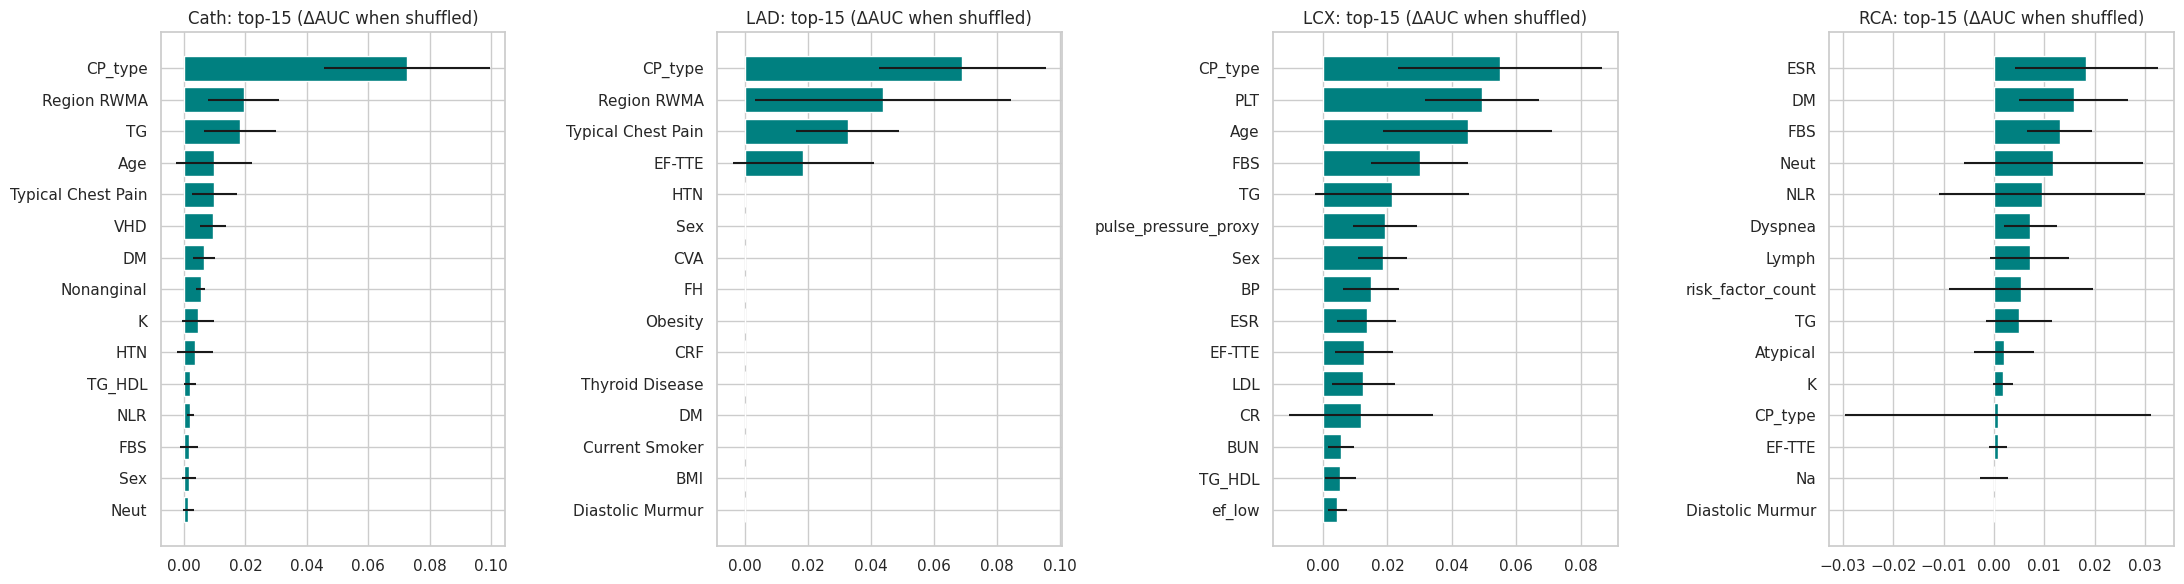

In [32]:
imp={}
for t in TARGETS:
    r=permutation_importance(best_est[t],X_te,Y_te[t],scoring='roc_auc',n_repeats=30,random_state=SEED,n_jobs=-1)
    imp[t]=pd.DataFrame({'importance':r.importances_mean,'std':r.importances_std},index=FEATURES).sort_values('importance',ascending=False)
    imp[t].to_csv(RES/f'{M}_perm_importance_{t}.csv')
fig,axes=plt.subplots(1,4,figsize=(22,6))
for ax,t in zip(axes,TARGETS):
    d=imp[t].head(15)[::-1]; ax.barh(d.index,d.importance,xerr=d['std'],color='teal'); ax.set_title(f'{t}: top-15 (ΔAUC when shuffled)')
plt.tight_layout(); plt.savefig(FIG/f'{M}_perm_importance.png',dpi=110); plt.show()

In [33]:
pd.concat({t:imp[t].head(10).importance.round(4).reset_index().rename(columns={'index':'feature'}) for t in TARGETS},axis=1)

Cath                            LAD                              LCX                           RCA           
              feature importance             feature importance               feature importance            feature importance
0             CP_type     0.0726             CP_type     0.0690               CP_type     0.0549                ESR     0.0184
1         Region RWMA     0.0194         Region RWMA     0.0439                   PLT     0.0493                 DM     0.0159
2                  TG     0.0182  Typical Chest Pain     0.0326                   Age     0.0449                FBS     0.0130
3                 Age     0.0099              EF-TTE     0.0184                   FBS     0.0300               Neut     0.0118
4  Typical Chest Pain     0.0098                 HTN     0.0000                    TG     0.0214                NLR     0.0095
5                 VHD     0.0094                 Sex     0.0000  pulse_pressure_proxy     0.0193            Dyspnea     0.0072
6                  DM     0.0066                 CVA     0.0000                   Sex     0.0185              Lymph     0.0071
7          Nonanginal     0.0054                  FH     0.0000                    BP     0.0148  risk_factor_count     0.0054
8                   K     0.0046             Obesity     0.0000                   ESR     0.0135                 TG     0.0050
9                 HTN     0.0037                 CRF     0.0000                EF-TTE     0.0127           Atypical     0.0019

## 16. Save fitted pipelines and probabilities

In [34]:
for t in TARGETS: joblib.dump(best_est[t],MOD/f'{M}_{t}.joblib')
joblib.dump(meta,MOD/f'{M}_stacked_Cath.joblib')
pd.DataFrame({t:test_proba[t] for t in TARGETS}|{'stacked_Cath':p_meta,'patient_idx':te.patient_idx.values}).to_csv(RES/f'{M}_test_proba.csv',index=False)
pd.DataFrame({t:oof[t] for t in TARGETS}|{'patient_idx':tr.patient_idx.values}).to_csv(RES/f'{M}_oof_train_proba.csv',index=False)
best_tbl.to_csv(RES/f'{M}_best_cv_summary.csv'); best_params.to_csv(RES/f'{M}_best_params.csv'); baseline.to_csv(RES/f'{M}_baseline.csv')
print('saved:',sorted(p.name for p in RES.glob(f'{M}_*'))[:30])

saved: ['xgb_baseline.csv', 'xgb_best_cv_summary.csv', 'xgb_best_params.csv', 'xgb_cv_fold_study.csv', 'xgb_cv_grid_Cath.csv', 'xgb_cv_grid_LAD.csv', 'xgb_cv_grid_LCX.csv', 'xgb_cv_grid_RCA.csv', 'xgb_cv_random_Cath.csv', 'xgb_cv_random_LAD.csv', 'xgb_cv_random_LCX.csv', 'xgb_cv_random_RCA.csv', 'xgb_nested_cv.csv', 'xgb_oof_train_proba.csv', 'xgb_perm_importance_Cath.csv', 'xgb_perm_importance_LAD.csv', 'xgb_perm_importance_LCX.csv', 'xgb_perm_importance_RCA.csv', 'xgb_test_metrics.csv', 'xgb_test_metrics_direct.csv', 'xgb_test_proba.csv']


## 17. Summary

In [35]:
summary=test_tbl[test_tbl.threshold_rule=='youden'].set_index('target')[['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].round(3)
summary.loc['Cath (stacked)']=st[st.threshold_rule=='youden'][['accuracy','balanced_acc','sensitivity','specificity','precision','f1','roc_auc','pr_auc']].iloc[0].round(3)
summary

,accuracy,balanced_acc,sensitivity,specificity,precision,f1,roc_auc,pr_auc
target,,,,,,,,
Cath,0.869,0.837,0.909,0.765,0.909,0.909,0.920,0.970
LAD,0.738,0.717,0.833,0.600,0.750,0.789,0.791,0.840
LCX,0.590,0.604,0.680,0.528,0.500,0.576,0.712,0.581
RCA,0.557,0.593,0.739,0.447,0.447,0.557,0.640,0.567
Cath (stacked),0.803,0.773,0.841,0.706,0.881,0.860,0.892,0.952
